# 2. zárthelyi dolgozat, B) változat (2025. 06. 06.)

**A második zárthelyi dolgozat során egy mély konvolúciós neuronhálót (CNN) tanítunk be egy bináris klasszifikációs feladatra a PyTorch könyvtár segítségével. A feladat során a repülni képes (röpképes) dolgokat (repülőgép, madár) ábrázoló fényképeket tanuljuk meg megkülönböztetni egyéb (röpkétpelen) dolgokat ábrázoló fényképektől. A neuronhálónk alapját egy, az ImageNet adatbázison előtanított mélyháló (a MobileNet 2) adja, melynek architektúráját kisebb átalakításokkal alkalmassá tesszük a feladatunk megoldására, majd finomhangoljuk azt. Mivel nem áll rendelkezésünkre sok címkézett kép a számunkra fontos kategóriákban, ezért adat-augmentációt is fogunk használni a betanításhoz.**

A zárthelyi több részfeladatból áll (A - G), melyek egymásra épülnek. A feladat automatikus tesztelőszkripttel rendelkezik és vizsgálja az egyes részfeladatokra adott megoldások helyességét. Éppen ezért, **ne változtasd meg a notebook struktúráját**, ne szedd több részre, illetve ne módosítsd a megírt részeket, csak a megoldásaidat írd be a megfelelő helyre, különben nem fogjuk tudni értékelni! A megoldások az `# Implement your solution BELOW` és `# Implement your solution ABOVE` sorok közé írandók. Ha a megoldott részfeladatok futtatásakor a "Tester: .... OK" felirat megjelenik, a tesztelőszkript nem talált hibát a megoldásban, azonban, a tesztelő nem teljeskörű, nem vesz észre mindenfajta hibát.

**A feladatban elérhető klasszifikációs pontosság:** Körülbelül 75-85% közti (bináris) accuracy érhető el a teszthalmazon a feladat helyes megoldásával. Ha ennél jelentősen rosszabb, vagy jelentősen jobb az eredmény, amit a neuronháló legfeljebb elér a teszthalmazon, akkor hibára lehet gyanakodni és meg kell próbálni azt megtalálni: a részfeladatok eredményeit össze lehet például vetni a feladatok szövegével és az eredeti, szöveges fájlban letöltött adatbázissal.

**A megoldott feladatsor beadása:** A kész megoldást tartalmazó notebookot (.ipynb) fájlként kell feltölteni a Canvas-ban, a "2. zárthelyi dolgozat pótlás" beadási felületén.

**További szabályok:**
- Kérjük a notebook szerkezetét nem módosítani és nem szétszedni külön feladatok szerint!
- A zárthelyi megoldásához, kizárólag, a Canvas feladatból letöltött .zip fájl tartalma és a Canvasban a saját profilból, már a ZH kezdetekor is elérhető tartalom használható fel. Kommunikáció csak az oktatókkal engedélyezett a ZH ideje alatt.

**Rendelkezésre álló idő:** 165 perc

**Értékelés:** Legfeljebb 40 pont gyűjthető: lásd a részfeladatokra adható pontokat az egyes feladatoknál. Minimum 20 pontot el kell érni ezen a zárthelyin a tárgy teljesítéséhez - ha ez nem sikerül, javító ZH megírása lesz szükséges.

**Kikötés:** Nagy számú iterációt (100+) végrehajtó ciklus és hasonló, nem hatékony konstrukció a kódban pontlevonást eredményezhet. Sok ezer pixelt felsoroló iteráció még inkább kerülendő! Kivételek, ahol büntetés nélkül használható hosszabb ciklus:
- Az A) feladatban a képek felsorolására (de nem a pixelek feletti iterálásra).
- A háló betanításánál/kiértékelésénél, a tanítási/validációs/teszt loopban, akár epoch-ok, akár batch-ek iterálására.
- A háló paramétereinek felsorolására.


---

Tesztelő szkript letöltése, importok.

In [79]:
# Use with local tester (./annbsc25_p1_zh2b_tester.py) & local image database file (./PascalVOC_annbsc_tiny.tar)

import os
import tarfile
import PIL
from PIL import Image
import io
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
import torchvision.transforms.v2
import skimage
import time

import matplotlib.pyplot as plt

from annbsc25_p1_zh2b_tester import Tester
tester = Tester()
print("Imports done")

Imports done


Az adatbázis beolvasása.

In [80]:
jpg_ims = []
label_ims = []

# unpacking tar content directly into memory and decoding jpg/png images from there to avoid working with many small files on disk
with tarfile.open("PascalVOC_annbsc_tiny.tar", "r") as tar:
    tar_members = tar.getmembers()
    tar_jpg_members = [member for member in tar_members if member.name[-4:] == '.jpg']  # list only jpg images, not label images
    for jpg_member in tar_jpg_members:
        filename_noext = os.path.split(jpg_member.name)[-1][:-4]

        # get next jpg image
        file_in_tar = tar.extractfile(jpg_member)
        byte_arr = np.asarray(bytearray(file_in_tar.read()), dtype=np.uint8)
        pil_image = Image.open(io.BytesIO(byte_arr))
        npy_image = np.asarray(pil_image)
        assert npy_image.dtype == np.uint8
        jpg_ims.append(npy_image)

        # get label image corresponding to the jpg image
        label_member_name = 'PascalVOC_annbsc_data/SegmentationClass/' + filename_noext + '.png'
        file_in_tar = tar.extractfile(label_member_name)
        byte_arr = np.asarray(bytearray(file_in_tar.read()), dtype=np.uint8)
        pil_image = Image.open(io.BytesIO(byte_arr))  # using PIL instead of cv2 as it supports loading palette coded png images as single channel integer arrays
        npy_image = np.asarray(pil_image)
        assert npy_image.dtype == np.uint8
        label_ims.append(npy_image)

jpg_ims = np.stack(jpg_ims, axis=0)
label_ims = np.stack(label_ims, axis=0)

# removing 'border region' (255) from label images and replacing it with background (0)
label_ims[label_ims == 255] = 0

print("Image & label data was loaded into 'jpg_ims', 'label_ims' NumPy arrays. Shapes:", jpg_ims.shape, label_ims.shape)


Image & label data was loaded into 'jpg_ims', 'label_ims' NumPy arrays. Shapes: (2913, 240, 320, 3) (2913, 240, 320)


**Adatbázis:** A feladat során a Pascal VOC adatbázis egy csökkentett felbontású részhalmazával kell dolgozni. Az adatbázisban húsz kategóriába (plusz "háttér") sorolt objektumokról készült képek vannak. A színes képekhez azonos felbontású szegmentációs címke tartozik, mely minden pixelre meghatározza annak szemantikus kategóriáját.

Az `(n_images, size_y=240, size_x=320, n_channels=3)` alakú, `np.uint8` adattípusú `jpg_ims` tömb tartalamazza a különböző állatokról, emberekről, járművekről és egyéb tárgyakról készült képeket. A `label_ims` tömb az említett képekhez rendelt szegmentációs címkéket tárolja. Ennek alakja `(n_images, size_y=240, size_x=320)`, adattípusa ugyancsak `np.uint8`. Az egy-egy képhez tartozó szegmentációs címke, a színes képekkel megegyező felbontású egycsatornás kép, mely minden egyes pixelre megadja az ahhoz rendelt szemantikus kategóriát egy integer formájában. Az adatbázis húsz fajta objektumot (élőlényt/tárgyat) különböztet meg, ezek 1 és 20 közti egész számokkal vannak reprezentálva. Azok a pixelek, melyek egyik kiemelt objektumtípushoz sem tartoznak, a "háttér" (background) kategóriába soroltak és 0 értéket kapnak a szegmentációs címkén.

Elsőként belenézünk a letöltött adatbázis tartalmába és kirajzolunk néhány képet a hozzájuk tartozó szegmentációs címkékkel együtt.

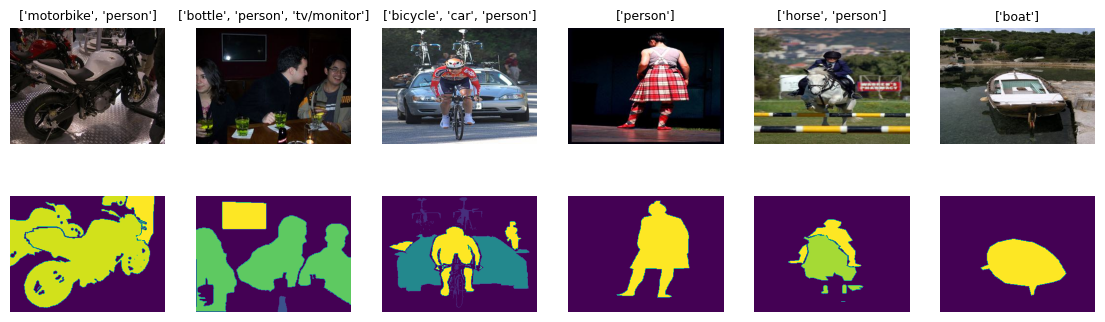

In [81]:
ORIG_CAT_NAMES = ['background', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'dining table', 'dog', 'horse', 'motorbike', 'person', 'potted plant', 'sheep', 'sofa', 'train', 'tv/monitor']

# implement your solution BELOW

sample_idxs = np.random.choice(jpg_ims.shape[0], size=6)
sample_jpg_ims = jpg_ims[sample_idxs,:,:,:]
sample_label_ims = label_ims[sample_idxs,:,:]

fig, axs = plt.subplots(2, 6)
fig.set_figheight(4)
fig.set_figwidth(14)
for plot_idx in range(6):
    axs[0, plot_idx].imshow(sample_jpg_ims[plot_idx])
    axs[1, plot_idx].imshow(sample_label_ims[plot_idx])
    axs[0, plot_idx].axis('off')
    axs[1, plot_idx].axis('off')
    u_labs = np.unique(sample_label_ims[plot_idx,:,:])
    text = str([ORIG_CAT_NAMES[lab] for lab in u_labs if lab > 0])
    axs[0, plot_idx].set_title(text, fontsize=9)


### **A**: A bináris klasszifikációhoz releváns képek kiválogatása - 5 + 2 + 4 pont

A következőkben kiválogatjuk a röpképes dolgokat (repülőgép, madár) ábrázoló képeket, majd választunk hozzá azonos mennyiségű, repülő dolgokat nem ábrázoló képet is. Ezt követően hozzuk létre a képeink címkéit tartalmazó tömböt is. Az így kapott adathalmazt fogjuk felhasználni a neuronhálónk betanítására és kiértékelésére.

#### **Alapfeladat**: 5 pont

Készítsd el az `imgs` és `labels` tömböket az alábbiak szerint!
- Kerüljön az `imgs` tömbbe az összes olyan kép a `jpg_ims` tömbből, mely legalább egy pixelnyi repülőgép (`aeroplane`), vagy madár (`bird`) kategóriát tartalmaz. A különböző objektumok jelenlétét a `label_ims` tömbben az adott képen jelen levő 1-es (repülőgép), és 3-as (madár) értékű pixelek jelzik.
- Válassz ki véletlenszerűen az előbbiekben választottakkal megegyező számú olyan képet, melyen sem repülőgép, sem madár nem található meg! Kerüljenek bele ezek is az `imgs` tömbbe.
- A `labels` tömb a fenti, kiválasztott képekhez rendel bináris klasszifikációs címkéket aszerint, hogy azok röpképes, vagy egyéb (rőképtelen) dolgokat ábrázolnak. Az, hogy melyik milyen kategóriaindexet kap, rád van bízva.

Az `imgs` tömb alakja tehát hasonló a `jpg_ims` tömbhöz, viszont kevesebb képet tartalmaz, hiszen az eredeti képeknek csak egy részét választottuk ki: `(n_kiválasztott_kép, 240, 320, 3)`. A `labels` tömb alakja ennek megfelelően `(n_kiválasztott_kép,)`: minden egyes képhez egy bináris klasszifikációs címkét tárol el.

**Javaslat:** olvasd végig az extra feladatokat is, mielőtt elkezdenél kódolni! Mindkettőt meg kell oldani a maximális pontszámért, nem alternatívái egymásnak. Ha nem tudod mindkettőt megoldani, a két extra feladat bármelyike önállóan is megoldható.

#### **Extra feladat #1**: további +2 pont

Hagyd figyelmen kívül azokat a röpképes dolgokat ábrázoló képeket, melyeken a röpképes eredeti kategóriák (repülőgép, madár) pixelei kizárólag a kép szélének 50 pixeles környezetében találhatók meg! Ezáltal, néhány, nehezen felismerhető képet kiszűrünk az adatbázisunkból. Figyelj rá, hogy az egyéb, röpképtelen dolgokat ábrázoló képekből is kevesebbet válassz, épp annyit, ahány röpképes dolgot ábrázoló képet megtartottunk! A röpképtelen dolgokat ábrázoló képek közé ne válaszd be a most eldobott, röpképes dolgokat ábrázoló képeket!

#### **Extra feladat #2**: további +4 pont

Hagyd figyelmen kívül azokat a röpképes dolgokat ábrázoló képeket, melyeken létezik olyan nem röpképes (nem madár, vagy repülőgép) egyedi előtér (`background` kivételével bármilyen) kategória, melybe önállóan több pixel van besorolva, mint a röpképes kategóriákba, együttvéve! Azaz, például, ha egy képen van 200 pixelnyi repülőgép és 100 pixelnyi madár, de emellett van 400 pixelnyi cserepes virág is, akkor ezt a képet eldobjuk. Figyelj rá, hogy az egyéb, röpképtelen dolgokat ábrázoló képekből is kevesebbet válassz, épp annyit, ahány röpképes dolgot ábrázoló képet megtartottunk! A röpképtelen dolgokat ábrázoló képek közé ne válaszd be a most eldobott, röpképes dolgokat ábrázoló képeket!


In [82]:
FLYING_ORIG_IDXS = {'aeroplane': 1, 'bird': 3}

# implement your solution BELOW

SOLUTION_1 = False
SOLUTION_2 = True
SOLUTION_3 = False

if SOLUTION_1:

    plane_idx = FLYING_ORIG_IDXS.get('aeroplane')
    bird_idx = FLYING_ORIG_IDXS.get('bird')

    flying_mask = np.any(label_ims == plane_idx, axis=(1,2)) | np.any(label_ims == bird_idx, axis=(1,2))
    flying_imgs = jpg_ims[flying_mask,:,:,:].copy()
    flying_labels = np.ones(flying_imgs.shape[0])
    non_flying_imgs = jpg_ims[~flying_mask, :, :, :]
    non_flying_imgs = non_flying_imgs[:flying_imgs.shape[0],:,:,:].copy()
    non_flying_labels = np.zeros(non_flying_imgs.shape[0])
    imgs = np.concatenate([flying_imgs, non_flying_imgs], axis=0)
    labels = np.concatenate([flying_labels, non_flying_labels], axis=0)


elif SOLUTION_2:
    plane_idx = FLYING_ORIG_IDXS.get('aeroplane')
    bird_idx = FLYING_ORIG_IDXS.get('bird')

    flying_mask = np.any(label_ims == plane_idx, axis=(1,2)) | np.any(label_ims == bird_idx, axis=(1,2))

    flying_inner_mask = np.any(label_ims[:,50:190,50:270] == plane_idx, axis=(1,2)) | np.any(label_ims[:,50:190,50:270] == bird_idx, axis=(1,2))
    flying_imgs = jpg_ims[flying_inner_mask,:,:,:].copy()
    flying_labels = np.ones(flying_imgs.shape[0])

    non_flying_imgs = jpg_ims[~flying_mask, :, :, :]
    non_flying_imgs = non_flying_imgs[:flying_imgs.shape[0],:,:,:].copy()
    non_flying_labels = np.zeros(non_flying_imgs.shape[0])

    imgs = np.concatenate([flying_imgs, non_flying_imgs], axis=0)
    labels = np.concatenate([flying_labels, non_flying_labels], axis=0)
    
elif SOLUTION_3:
    plane_idx = FLYING_ORIG_IDXS.get('aeroplane')
    bird_idx = FLYING_ORIG_IDXS.get('bird')
    flying_mask = np.any(label_ims == plane_idx, axis=(1,2)) | np.any(label_ims == bird_idx, axis=(1,2))
    
    other_cat_mask_on_pixels = (label_ims[flying_mask] != plane_idx) & (label_ims[flying_mask] != bird_idx) & (label_ims[flying_mask] != 0)
    other_cat_pixel_count = np.count_nonzero(other_cat_mask_on_pixels, axis=(1,2))
    
    flying_mask_on_pixels = (label_ims == plane_idx) | (label_ims == bird_idx)
    flying_cat_pixel_count = np.count_nonzero(flying_mask_on_pixels, axis=(1,2))
    
    flying_majority_mask = (flying_cat_pixel_count > other_cat_pixel_count) & flying_mask

    flying_imgs = jpg_ims[flying_majority_mask].copy()
    flying_labels = np.ones(flying_imgs.shape[0])

    non_flying_imgs = jpg_ims[~flying_mask]
    non_flying_imgs = non_flying_imgs[:flying_imgs.shape[0],:,:,:].copy()
    non_flying_labels = np.zeros(non_flying_imgs.shape[0])

    imgs = np.concatenate([flying_imgs, non_flying_imgs], axis=0)
    labels = np.concatenate([flying_labels, non_flying_labels], axis=0)
    
print(imgs.shape)
print(labels.shape)
# implement your solution ABOVE

tester.test('A', imgs, labels)

(760, 240, 320, 3)
(760,)
Tester: Task A - Alapfeladat & Extra feladat #1 OK. Extra feladat #2 missing.



### **B**: Felbontás tanító-, validációs- és teszthalmazra - 3 pont

**Keverd meg véletlenszerűen a mintaelemeket** az adatbázisban! Ezt általánosságban azért célszerű megtenni, mert az adatbázisban az elemek valamilyen tulajdonságaik alapján rendezve lehetnek. Megkeverés nélkül, a szétválasztott halmazokban jelentősen különbözne a címkék eloszlása. Figyelj rá, hogy a keverés azonos sorrendű legyen az `imgs` és a `labels` tömb elemein!

Ezt követően **válaszd szét** (konzisztens módon) **a megkevert, képeket tartalmazó tömböt és az ahhoz tartozó címketömböt tanító-, validációs- és teszthalmazra**! Kerüljön 150-150 mintaelem a validációs- és teszthalmazba, majd a maradék a tanítóhalmazba (a sorrend mindegy)!  Állítsuk elő így, az

  - `imgs_train`, `imgs_val`, `imgs_test` nevű, képeket tartalmazó tömböket, illetve, a hozzájuk tartozó
  - `labels_train`, `labels_val`, `labels_test` nevű címketömböket!


In [83]:
# implement your solution BELOW
permutation = np.random.permutation(imgs.shape[0])
imgs = imgs[permutation, :, :, :]
labels = labels[permutation]


imgs_test = imgs[:150,:,:,:]
print(imgs_test.shape)
imgs_val = imgs[150:300,:,:,:]
print(imgs_val.shape)
imgs_train = imgs[300:,:,:,:]
print(imgs_train.shape)

labels_test = labels[:150]
labels_val = labels[150:300]
labels_train = labels[300:]
# implement your solution ABOVE

tester.test('B', imgs_train,   imgs_val,   imgs_test, \
                 labels_train, labels_val, labels_test)

(150, 240, 320, 3)
(150, 240, 320, 3)
(460, 240, 320, 3)
Tester: Task B - OK


### **C**: Az adat-iterátorok létrehozása a bináris klasszifikációs feladathoz, adat-augmentáció - 5 pont

A házi feladatokhoz és az előző zárthelyihez hasonlóan, ezúttal is iterátorokkal oldjuk meg a neuronhálónk betanítását. Ebben a részfeladatban **elő kell állítanod három iterátor objektumot** `dataloader_train`, `dataloader_val` és `dataloader_test` néven, melyek az előző részfeladatban elkészített megfelelő részhalmazhoz tartozó röpképes és röpkételen dolgokat ábrázoló képtömb-címketömb párosokból sorolják fel a képeket és a hozzájuk tartozó bináris klasszifikációs címkéket!

Például, a `dataloader_train` iterátor az `imgs_train` és a `labels_train` tömbökből sorolja fel a képeket és a hozzájuk tartozó címkéket. Hasonlóan, a validációs és a teszt iterátor a további két képtömb-címketömb párossal dolgozik.

**A képek felbontását a kötegekbe sorolás előtt csökkentjük** 128 x 128 pixelre, azért, hogy a neuronhálónk számításigénye kisebb legyen. Ezt megteheted, többek közt, a NumPy tömbökön operáló `skimage.transform.resize()` függvénnyel, vagy később, a `torchvision.transforms.v2` pipeline-jában is (`
torchvision.transforms.v2.Resize` osztály). Utóbbi használata esetén, a `Resize` példányt a tenzorrá alakítást követően kell elvgezned a pipeline-ban. Fontos, hogy ne képkivágást használj, hanem átméretezést, hiszen a képkivágás elképzelhető, hogy levágná a lényeget a képről.

**Az iterátorok minden lépésben két tenzort adnak vissza**, melyek egy-egy kötegnyi input képet és azokhoz tartozó bináris klasszifikációs címkéket tartalmaznak.

A képek esetén szükséges lesz a tengelyek sorrendjének átrendezése, mivel a csatornákat felsoroló tengely eddig hátul volt (_channel-last_ formátum: NHWC), de a PyTorch erre a tengelyre közvetlenül a kötegméret tengely után számít (_channel-first_ formátum: NCHW). Ebből kifolyólag, a visszaadott tenzorok alakja `(batch_size, 3, 128, 128)` és `(batch_size, 1)` lesz. Előbbi a színes képeket tartalmazza, utóbbi a képekhez tartozó bináris klasszifikációs címkéket. `batch_size` a mintaelemek számát adja meg, melyeket egyszerre, egy kötegben fog megkapni a neuronhálónk - ennek értéke lehet például 32.

Hangsúlyozandó, hogy az iterátorok a fent említett NumPy tömbökből (`np.ndarray`) nyert mintaelem-kötegeket már `torch.tensor` típusú objektumokként adják vissza (pontosabban, kételemű tuple-öket adnak vissza, melyekben `torch.tensor` objektumok lesznek). A PyTorch-al definiált neuronhálók betanításához már mindenképp PyTorch tenzorok szükségesek: az input tenzor és a bináris címkéket tartalmazó tenzor **adattípusa** is 4 bájtos lebegőpontos típus (`torch.float32`) kell, hogy legyen.

A neuronhálónk egy előtanított mély konvolúciós hálón alapul majd, ezért a képeinket olyan formátumra kell hoznunk, amilyet a háló a betanításakor látott. Az eredetileg [0, 255] intervallumbeli értékeket tartalmazó képeinket először a [0, 1] intervallumra kell leskáláznunk, majd színcsatornánként megadott átlag (`MOBILENET_MEANS`) és szórás (`MOBILENET_STDS`) értékekkel kell sztenderdizálnunk. Az iterátor által visszaadott képek színcsatornánként függetlenül vett átlaga tehát 0 körül, szórása pedig 1 körül lesz a helyes sztenderdizáció után.

Az iterátorok implementációja többféleképpen megoldható. Például, egyedi generátorral/iterátorral, vagy a `torch.utils.data` modul `Dataset` és `DataLoader` osztályai felhasználásával és esetleges származtatásával.

**Adat-augmentáció:** Sajnos a néhány száz képből álló adatbázisunkra hamar túltanulna a hálónk és nincs lehetőségünk új tanítóadatot beszerezni, így az adat-augmentálás technikájához kell fordulnunk. Azért, hogy valóban növeljük az adatbázisunkban a képek változatosságát, az adat-augmentációt nem előzetesen alkalmazzuk az egész adatbázison egyben, hanem dinamikusan hajtjuk végre, véletlenszerűen választott transzformációkkal minden újabb mintaelemen, vagy kötegen.

Alkalmazz véletlenszerű adat-augmentációt a **tanító** iterátorban, hogy csökkentsd a túltanulás valószínűségét! Az adat-augmentációs módszerek közt legyen kis méretékű transzláció (eltolás), forgatás, skálázás, zaj, illetve a kép színeinek torzítása! A validációs- és teszt-iterátorok ne alkalmazzank adat-augmentációt, hiszen ezeket kiértékeléshez fogjuk használni! Az adat-augmentációhoz javasolt (de nem kötelező) a `torchvision.transforms.v2` modul eszközeit használni. Ennek segítségével a sztenderdizáció is megoldható.


In [84]:
MOBILENET_MEANS = [0.485, 0.456, 0.406]
MOBILENET_STDS = [0.229, 0.224, 0.225]   # MobileNet v2 stats used for image normalization

# implement your solution BELOW

class ImageClassificationDataset(Dataset):
    def __init__(self, imgs, labels, transform):
        self.transform = transform
        self.xs = imgs
        self.ys = torch.from_numpy(labels[:,None]).to(torch.float32)

    def __len__(self):
        return self.xs.shape[0]

    def __getitem__(self, idx):
        x = self.xs[idx,:,:,:]
        x = self.transform(x)
        y = self.ys[idx]
        return x, y

train_transform_ls = [
    transforms.v2.ToImage(),                             # ndarray(H, W, C) uint8 range in [0, 255] -> Tensor(C, H, W) uint8 range in [0, 255]
    transforms.v2.ToDtype(torch.float32, scale=True),   # Tensor(C, H, W) uint8 range in [0, 255] -> Tensor(C, H, W) fl32 range in [0, 1] as 'scale=True'
    torchvision.transforms.v2.Resize(size=(128, 128)),
    transforms.v2.RandomHorizontalFlip(),
    transforms.v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.v2.RandomAffine(degrees=15., translate=(0.2, 0.2), scale=(0.8, 1.2)),
    transforms.v2.Normalize(mean=MOBILENET_MEANS, std=MOBILENET_STDS)                 # LINE ADDED
]

eval_transform_ls = [
    transforms.v2.ToImage(),                             # ndarray(H, W, C) uint8 range in [0, 255] -> Tensor(C, H, W) uint8 range in [0, 255]
    transforms.v2.ToDtype(torch.float32, scale=True),    # Tensor(C, H, W) uint8 range in [0, 255] -> Tensor(C, H, W) fl32 range in [0, 1] as 'scale=True'
    torchvision.transforms.v2.Resize(size=(128, 128)),
    transforms.v2.Normalize(mean=MOBILENET_MEANS, std=MOBILENET_STDS)                 # LINE ADDED
]

train_transform = transforms.v2.Compose(train_transform_ls)
eval_transform = transforms.v2.Compose(eval_transform_ls)

train_dataset = ImageClassificationDataset(imgs_train, labels_train, transform=train_transform)   # data-augmentation only here
val_dataset = ImageClassificationDataset(imgs_val, labels_val,  transform=eval_transform)          # no need to augment during validation
test_dataset = ImageClassificationDataset(imgs_test, labels_test, transform=eval_transform)       # no need to augment during test

dataloader_train = DataLoader(train_dataset, batch_size=32, shuffle=True)
dataloader_val = DataLoader(val_dataset, batch_size=32, shuffle=True)
dataloader_test = DataLoader(test_dataset, batch_size=32, shuffle=False)  # not shuffling!

# implement your solution ABOVE

tester.test('C', dataloader_train, dataloader_val, dataloader_test)

Tester: Task C - OK


### **D**: A konvolúciós háló definiálása bináris klasszifikációhoz - 6 pont

A konvolúciós hálónk alapját egy, az ImageNet adatbázison előtanított MobileNet v2 neuronháló adja. Ezt alapul véve (és a tanult súlyainak nagyrészét felhasználva) készítjük el a célfeladat megoldására alkalmas neuronhálónkat, amit finomhangolunk az adatbázisunkon.

**Definiáld a bináris klasszifikációs feladathoz alkalmazandó neuronhálót megvalósító osztályt**, mely az általános `torch.nn.Module` osztály leszármazottja!

Töltsd be a MobileNet v2 neuronhálót előtanított súlyokkal, majd ennek egyik utolsó konvolúciós rétegéhez (ajánlott: `features[17].conv[3]`) fűzz hozzá

**egyetlen teljesen összekötött réteget (!)**,

ami már a bináris klasszifikációhoz szükséges kimenetet adja! Aktivációs függvény(eke)t ennek megfelelően kell alkalmaznod! Mivel szükséges, hogy nagyon rövid idő alatt betanítható legyen ez a háló, fagyaszd be az előtanított MobileNet hálóhoz tartozó paramétereket (azaz ne legyenek ezek a paraméterek taníthatóak).

**Példányosítsd az új osztályt** és add értékül a `finetuned_model` nevű változónak a példányt!


In [85]:

'''

# In order to load the MobileNet v2 pre-trained weights without internet access
# REPLACE THIS LINE:

self.mobile_net = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', weights='MobileNet_V2_Weights.IMAGENET1K_V1')

# WITH THESE FOUR LINES:

self.mobile_net = torch.hub.load(repo_or_dir='./mobilenet_weights/', model='mobilenet_v2', source='local')
checkpoint = os.path.join('./mobilenet_weights/', 'mobilenet_v2-b0353104.pth')
mobile_net_state_dict = torch.load(checkpoint, weights_only=True)
self.mobile_net.load_state_dict(mobile_net_state_dict)

'''

# implement your solution BELOW


class MobileNet2_FineTunedForBinaryClassification(nn.Module):

    def __init__(self):
        super().__init__()
        self.mobile_net = torch.hub.load(repo_or_dir='./mobilenet_weights/', model='mobilenet_v2', source='local')
        checkpoint = os.path.join('./mobilenet_weights/', 'mobilenet_v2-b0353104.pth')
        mobile_net_state_dict = torch.load(checkpoint, weights_only=True)
        self.mobile_net.load_state_dict(mobile_net_state_dict)
        self.mobile_net_output = None
        self.mobile_net.features[17].conv[3].register_forward_hook(self._hook)
        for param in self.mobile_net.parameters():            # freeze all weights of the original MobileNet network
          param.requires_grad = False                         #      good if we have very little training data and our task is related to an image classification task on ImageNet
                                                              #      bad if our task is highly different from an image classification task on ImageNet

        self.extra_fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(320*4*4, 1),
            nn.Sigmoid(),
        )

    def _hook(self, module, input, output):
        self.mobile_net_output = output

    def forward(self, x):
        _ = self.mobile_net(x)
        out = self.extra_fc(self.mobile_net_output)
        return out

# instantiate net class

finetuned_model = MobileNet2_FineTunedForBinaryClassification()
#print(finetuned_model)

# implement your solution ABOVE

tester.test('D', finetuned_model)

Tester: Task D might be OK. Note, that the exact architecture is not checked with this test.


### **E**: Néhány augmentált kép kirajzolása - 1 pont

Azért, hogy lássuk, a hálónk megfelelő inputot és címkéket fog kapni, mintavételezünk pár képet és címkét a C) feladatban elkészített iterátorokból és kirajzoljuk ezeket.
- Mintavételezz néhány képet és a hozzájuk tartozó címkéket a `dataloader_train` és `dataloader_val` iterátorokból, majd rajzold ki ezeket a képeket és írd föléjük a hozzájuk tartozó klasszifikációs címkét ("0", vagy "1")! Mivel az iterátorok a képeket normalizálják és megváltoztatják a tengelysorrendet is, a helyes kirajzoláshoz ezeket a transzformációkat vissza kell csinálnod a kirajzolás előtt.

_**Megjegyzés:** Itt tudod ellenőrizni, hogy egyrészt az adat-augmentáció helyes-e, másrészt, hogy helyes kategóriacímkék tartoznak-e a képekhez, harmadrészt, hogy vegyesen tartalmaznak-e a kötegek repülni tudó és röpképtelen dolgokat._

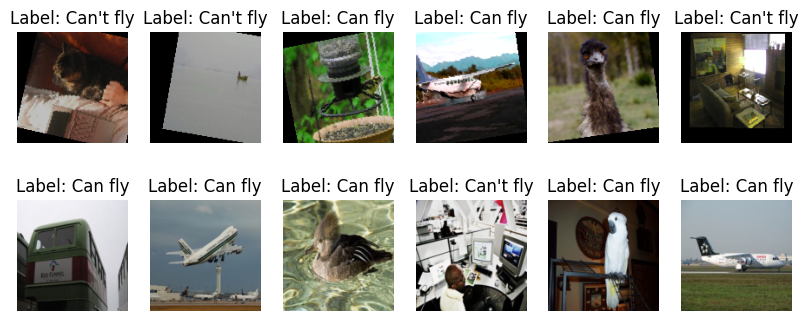

In [86]:
# implement your solution BELOW (No automatic tests for this task)

for sample_xs_train, sample_ys_train in dataloader_train:
  sample_xs_train = sample_xs_train.permute(0, 2, 3, 1)
  sample_xs_train = sample_xs_train.numpy()
  sample_xs_train = (sample_xs_train * MOBILENET_STDS) + MOBILENET_MEANS
  sample_xs_train = np.clip(sample_xs_train, 0, 1)
  sample_ys_train = sample_ys_train.numpy()
  break

for sample_xs_val, sample_ys_val in dataloader_val:
  sample_xs_val = sample_xs_val.permute(0, 2, 3, 1)
  sample_xs_val = sample_xs_val.numpy()
  sample_xs_val = (sample_xs_val * MOBILENET_STDS) + MOBILENET_MEANS
  sample_xs_val = np.clip(sample_xs_val, 0, 1)
  sample_ys_val = sample_ys_val.numpy()
  break

N_COLS = 6
label_dict = {"[0.]":"Can't fly", "[1.]":"Can fly"}
fig, axes = plt.subplots(2, N_COLS, figsize=(10,4))
for col_idx in range(N_COLS):
    axes[0, col_idx].imshow(sample_xs_train[col_idx,:,:,:])
    axes[0, col_idx].axis('off')
    axes[0, col_idx].set_title("Label: " + label_dict.get(str(sample_ys_train[col_idx])))
    axes[1, col_idx].imshow(sample_xs_val[col_idx,:,:,:])
    axes[1, col_idx].axis('off')
    axes[1, col_idx].set_title("Label: " + label_dict.get(str(sample_ys_val[col_idx])))








### **F**: A háló betanítása bináris klasszifikációs feladatra - 5 pont

**Tanítsd be a** `finetuned_model` **neuronhálót** a tanítóhalmazon a `dataloader_train` iterátor segítségével és alkalmazd a `dataloader_val` iterátort a validációhoz!

Alkalmazd a bináris klasszifikációkor szokásosan használt költséget! **Mérd le minden epoch-ban a tanító- és a validációs halmazon mért költségeket, majd a tanítás végeztével rajzold ki ezeknek az értékeknek a tanítás során való alakulását egy közös grafikonon!** A grafikonon a jelmagyarázat meglétére és a görbék könnyű elkülöníthetőségére figyelj ezúttal is! **Számold ki a (bináris) _accuracy_ (pontosság) metrikát minden epoch-ban a tanító- és a validációs halmazon** és jelöld ezek alakulását is a grafikonon!

A tanítást az **early stopping** technika állítsa le! Amennyiben adott számú epoch-on keresztül (`patience`) nem javul a validációs költség, érjen véget a betanítás és **állítsuk vissza az `finetuned_model` súlyait abból az epoch-ból, amikor a legjobb volt a validációs költség!** Mindez automatikusan történjen!

A betanítást követően **számold ki a _(bináris) accuracy_ metrikát a teszt-iterátorból mintavételezett példahalmazon** és add értékül a kapott számot a `test_acc` változónak!

_**Megjegyzés:** Megfelelően választott tanulási rátával 1 perc (CPU) tanítás elegendő a tesztelő által elvárt metrikák eléréséhez (akár 2-3 epoch)._

Epoch #0, tr loss: 0.5958259105682373, val loss: 0.4719962179660797, tr acc: 0.7250000238418579, val acc: 0.8227273225784302
    Early stopping: Best model updated.
Epoch #1, tr loss: 0.4700535237789154, val loss: 0.3977413773536682, tr acc: 0.826388955116272, val acc: 0.8471590876579285
    Early stopping: Best model updated.
Epoch #2, tr loss: 0.43259093165397644, val loss: 0.38337045907974243, tr acc: 0.8208333253860474, val acc: 0.8482953906059265
    Early stopping: Best model updated.
Epoch #3, tr loss: 0.3872380554676056, val loss: 0.36156758666038513, tr acc: 0.8374999761581421, val acc: 0.8789772987365723
    Early stopping: Best model updated.
Epoch #4, tr loss: 0.41392722725868225, val loss: 0.3556380271911621, tr acc: 0.8187500238418579, val acc: 0.8636363744735718
    Early stopping: Best model updated.
Epoch #5, tr loss: 0.3571982681751251, val loss: 0.35653430223464966, tr acc: 0.8652777075767517, val acc: 0.8727272748947144
Epoch #6, tr loss: 0.3766155242919922, val los

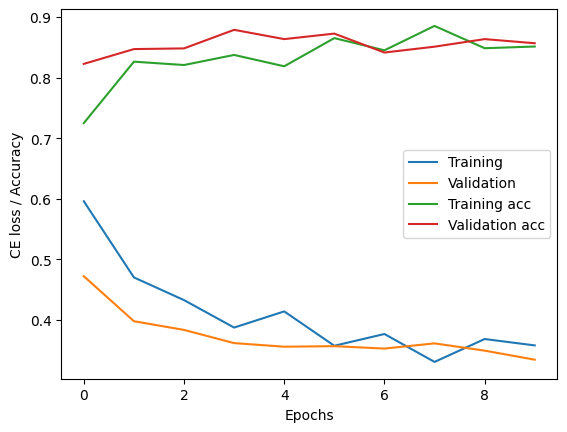

Tester: Task F  - achieved metrics are OK.


In [87]:
# implement your solution BELOW

@torch.no_grad()
def acc_fn(y_hat, y_true):
      return torch.count_nonzero(torch.round(y_hat) == y_true) / y_hat.shape[0]

loss_fn = nn.BCELoss()

n_epochs = 10
learning_rate = 0.001
optimizer = torch.optim.Adam(finetuned_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracy = []
val_accuracy = []
best_cl_model = None
best_val_loss = float('inf')
early_stopping_patience = 3
last_early_stopping_update_ep_idx = 0

for epoch_idx in range(n_epochs):
  finetuned_model.train()
  train_epoch_losses = []
  train_epoch_accs = []

  for x, y in dataloader_train:

    optimizer.zero_grad()
    y_hat = finetuned_model(x)
    loss = loss_fn(y_hat, y)
    acc = acc_fn(y_hat, y)
    train_epoch_losses.append(loss.detach())     
    train_epoch_accs.append(acc)                  
    loss.backward()
    optimizer.step()


  train_epoch_losses = torch.tensor(train_epoch_losses)
  train_epoch_accs = torch.tensor(train_epoch_accs)
  avg_tr_epoch_loss = train_epoch_losses.mean()
  avg_tr_epoch_acc = train_epoch_accs.mean()
  train_losses.append(avg_tr_epoch_loss)
  train_accuracy.append(avg_tr_epoch_acc)

  finetuned_model.eval()
  val_epoch_losses = []
  val_epoch_accs = []

  for x, y in dataloader_val:
    with torch.no_grad():
      y_hat = finetuned_model(x)

    loss = loss_fn(y_hat, y)
    acc = acc_fn(y_hat, y)
    val_epoch_losses.append(loss)         
    val_epoch_accs.append(acc)       

  val_epoch_losses = torch.tensor(val_epoch_losses)
  val_epoch_accs = torch.tensor(val_epoch_accs)
  avg_val_epoch_loss = val_epoch_losses.mean()
  avg_val_epoch_acc = val_epoch_accs.mean()
  val_losses.append(avg_val_epoch_loss)
  val_accuracy.append(avg_val_epoch_acc)

  print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}, tr acc: {avg_tr_epoch_acc}, val acc: {avg_val_epoch_acc}")

  # early stopping: check if current weights give the lowest ever loss
  if avg_val_epoch_loss < best_val_loss:
    best_val_loss = avg_val_epoch_loss
    best_cl_model = copy.deepcopy(finetuned_model)       
    last_early_stopping_update_ep_idx = epoch_idx
    print("    Early stopping: Best model updated.")

  # early stopping: break if no update for a long time
  if last_early_stopping_update_ep_idx + early_stopping_patience < epoch_idx:
    print("Training is terminated by early stopping.")
    break

# early stopping: restore best weights
print("Best model weights are restored.")
finetuned_model = best_cl_model               


test_pred_y_cat = []
test_y_cat = []
test_imgs = []

with torch.no_grad():
    _, (test_x, test_y) = next(enumerate(dataloader_test))
    test_pred_y_cat_batch_npy = torch.round(finetuned_model(test_x)).numpy()      
    test_pred_y_cat.append(test_pred_y_cat_batch_npy)
    test_y_cat.append(test_y.numpy())
test_pred_y_cat = np.concatenate(test_pred_y_cat, axis=0)
test_y_cat = np.concatenate(test_y_cat, axis=0)

with torch.no_grad():

  test_pred_ys = []
  test_ys = []
  for x, y in dataloader_test:
    y_hat = finetuned_model(x)
    test_pred_ys.append(y_hat)
    test_ys.append(y)
    

  test_pred_ys = torch.cat(test_pred_ys, dim=0)
  test_ys = torch.cat(test_ys, dim=0)
  test_loss = loss_fn(test_pred_ys, test_ys)
  test_acc = acc_fn(test_pred_ys, test_ys)

plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.plot(train_accuracy, label='Training acc')
plt.plot(val_accuracy, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('CE loss / Accuracy')
plt.legend()
plt.show()






# implement your solution ABOVE

tester.test('F', test_acc)

### **G**: Valós/fals - pozitív/negatív példa képek kirajzolása - 5 + 4 pont

Adj becslést a neuronhálóval a teszthalmaz képeire! Alkoss négy csoportot a képekből:
- Helyesen klasszifikált röpképes dolgokat ábrázoló képek.
- Hibásan (röpképtelennek) klasszifikált röpképes dolgokat ábrázoló képek.
- Helyesen klasszifikált röpképtelen dolgokat ábrázoló képek.
- Hibásan (röpképesnek) klasszifikált röpképtelen dolgokat ábrázoló képek.

#### **Alapfeladat**: 5 pont

Rajzolj ki mind a négy csoportból néhány képet, csoportok szerint elkülönítve, és írd az egyes képek fölé annak a becsült valószínűségét, hogy az adott képeken röpképes dolgok vannak!

#### **Extra feladat**: további 4 pont

Rendezd az egyes csoportokba tartozó képeket a becslés magabiztossága szerint csökkenő sorrendbe (csoportonként függetlenül) és a sorrend szerinti első néhány (azaz, a legmagabiztosabban becsült néhány) képet rajzold ki minden csoportból! A becslés magabiztossága nem annak helyességét jelenti, hanem azt, hogy a becsült valószínűség mennyire van közel 0-hoz, vagy 1-hez (a kettő közül a közelebbihez).

**Példa:** a 0.1-es becsült valószínűség magabiztosabb, mint a 0.8, de kevésbé magabiztos, mint a 0.95.

Tehát, például a fenti felsorolás szerinti második csoportból ("Hibásan (röpképtelennek) klasszifikált röpképes dolgokat ábrázoló képek") a legmagabiztosabban hibásnak (azaz, leginkább röpképtelennek) klasszifikált néhány képet kell kirajzolni.


TypeError: Invalid shape (0, 32, 128, 128, 3) for image data

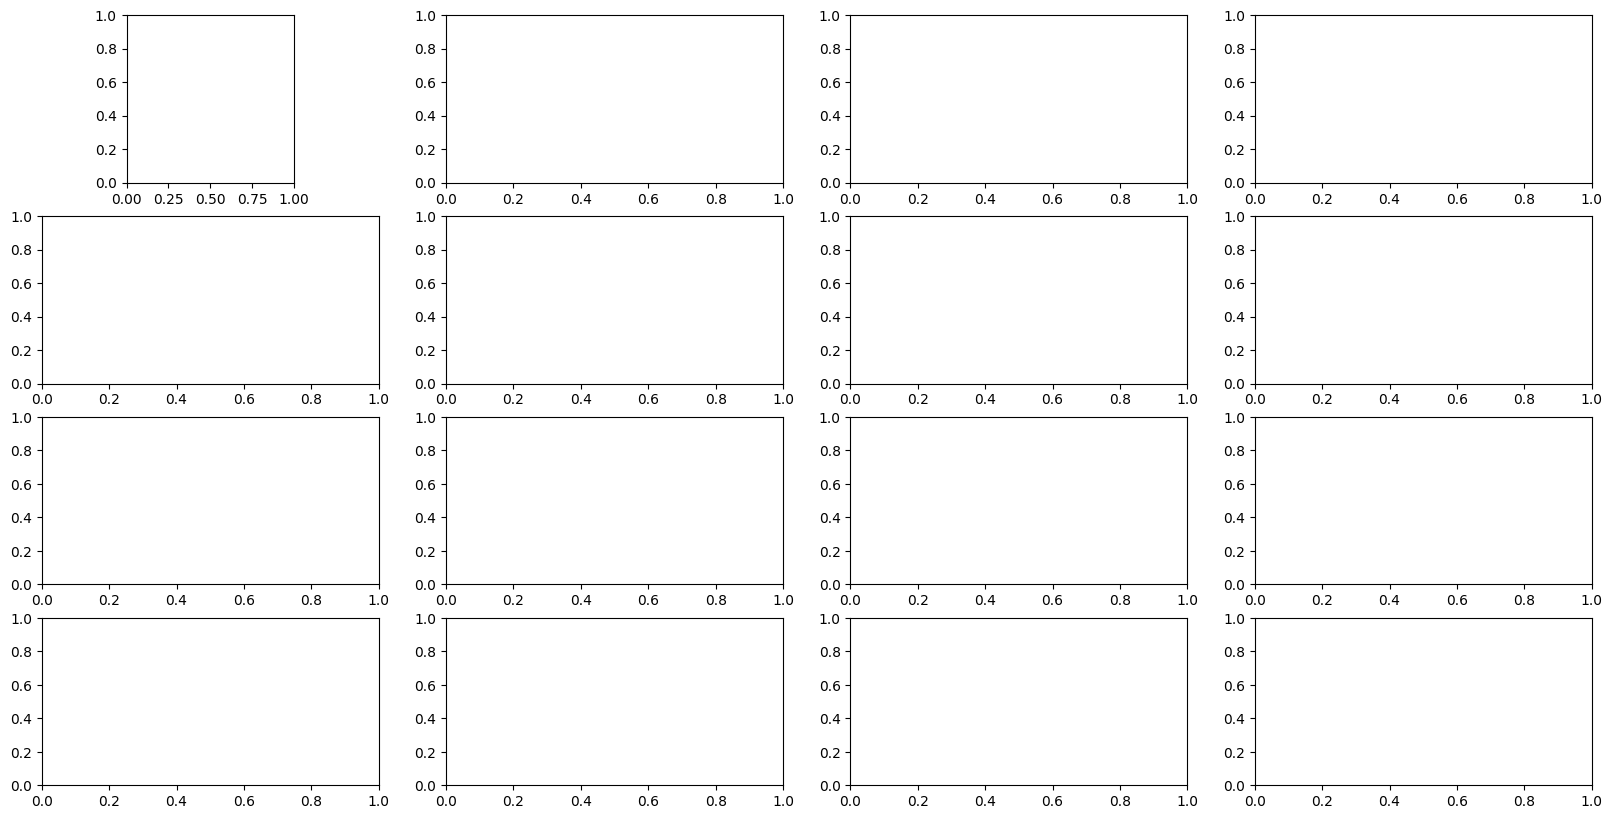

In [106]:
# implement your solution BELOW (No automatic tests for this task)
plot_preds=np.array([])
plot_labels=np.array([])
plot_imgs=np.array([])



for x, y in dataloader_test:
    with torch.no_grad():
      y_hat = torch.round(finetuned_model(x)).numpy()
    x = x.permute(0, 2, 3, 1)
    x = x.numpy()
    x = (x * MOBILENET_STDS) + MOBILENET_MEANS
    x = np.clip(x, 0, 1)
    plot_imgs.append(x)
    plot_preds.append(y_hat)
    plot_labels.append(y)

true_positive_mask = (plot_preds == 1) & (plot_labels == 1)
false_positive_mask = (plot_preds == 1) & (plot_labels == 0)
true_negative_mask = (plot_preds == 0) & (plot_labels == 0)
false_negative_mask = (plot_preds == 0) & (plot_labels == 1)

subarrays = {"True positive" : test_imgs[true_positive_mask], "False positive" :  test_imgs[false_positive_mask], "True negative" : test_imgs[true_negative_mask], "False negative" : test_imgs[false_negative_mask]}
N_COLS = 4
N_ROWS = 4
label_dict = {"[0.]":"Can't fly", "[1.]":"Can fly"}
fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(20,10))
for row_idx in range(N_ROWS):
    keys = list(subarrays.keys())
    for col_idx in range(N_COLS):
        axes[row_idx, col_idx].imshow(subarrays.get(keys[col_idx])[:,row_idx,:,:,:])
        axes[row_idx, col_idx].axis('off')
        axes[row_idx, col_idx].set_title(keys[col_idx])


